# Atividade 3 — Processamento de Linguagem Natural (PLN)

Esta atividade reúne as três primeiras questões da lista 3, sobre a mesma base de tweets das Atividades 1 e 2: agrupamento com k-means e coeficiente de silhueta, projeção multidimensional com t-SNE e buscadores de palavras e documentos com um modelo word2vec pré-treinado. As Questões 4 (redes LSTM e Conv1D) e 5 (spaCy) não fazem parte desta entrega.

**Integrantes:**

- José Anderson da Silva
- Otto Tenório de Albuquerque Lins Bisneto

# Preparação da base

**Base de dados:** o mesmo `Tweets.csv` da [Twitter US Airline Sentiment (Kaggle)](https://www.kaggle.com/datasets/drnimishadavis/twitter-us-airline-sentiment) usado nas Atividades 1 e 2.

**Pré-processamento:** a lista 3 pede a base "após os pré-processamentos realizados na lista 1". Reproduzimos, sem alterações, a função `preprocessar_texto` da Questão 5 da Atividade 1 (a mesma usada na Atividade 2): remoção de palavras com dígitos, minúsculas, remoção de pontuação e tokenização por espaços. Tweets que ficam vazios são excluídos. A Questão 3 acrescenta a remoção de stopwords e o filtro por vocabulário do modelo, como o próprio enunciado exige.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
from IPython.display import display

caminho_base = next(
    (p for p in [Path('dados/Tweets.csv'), Path('Tweets.csv')] if p.is_file()),
    None,
)
if caminho_base is not None:
    tweets = pd.read_csv(caminho_base, dtype={'tweet_id': 'string'})
else:
    # No Colab, permite selecionar o CSV no computador.
    try:
        from google.colab import files
    except ImportError:
        raise FileNotFoundError('Coloque Tweets.csv na pasta dados ou ao lado do notebook.')
    from io import BytesIO
    enviados = files.upload()
    if 'Tweets.csv' not in enviados:
        raise FileNotFoundError('Selecione o arquivo Tweets.csv e execute novamente.')
    tweets = pd.read_csv(BytesIO(enviados['Tweets.csv']), dtype={'tweet_id': 'string'})

print(f'Registros carregados: {len(tweets)}')
display(tweets[['tweet_id', 'airline', 'airline_sentiment', 'text']].head())

Registros carregados: 14640


,tweet_id,airline,airline_sentiment,text
0,570306133677760513,Virgin America,neutral,@VirginAmerica What @dhepburn said.
1,570301130888122368,Virgin America,positive,@VirginAmerica plus you've added commercials t...
2,570301083672813571,Virgin America,neutral,@VirginAmerica I didn't today... Must mean I n...
3,570301031407624196,Virgin America,negative,@VirginAmerica it's really aggressive to blast...
4,570300817074462722,Virgin America,negative,@VirginAmerica and it's a really big bad thing...


In [2]:
import string
import unicodedata

def preprocessar_texto(texto):
    # Reproduz, sem alterações, o pré-processamento da Questão 5 da Atividade 1.
    # 1. Remove o elemento inteiro se ele contiver algum dígito.
    sem_numeros = [palavra for palavra in texto.split()
                   if not any(c.isdigit() for c in palavra)]
    # 2. Converte para minúsculas.
    minusculo = ' '.join(sem_numeros).lower()
    # 3. Apaga pontuação ASCII e Unicode.
    sem_pontuacao = ''.join(
        c for c in minusculo
        if c not in string.punctuation
        and not unicodedata.category(c).startswith('P')
    )
    # 4. Tokeniza em palavras.
    return sem_pontuacao.split()

tweets['tokens'] = tweets['text'].map(preprocessar_texto)
tweets['texto_processado'] = tweets['tokens'].map(' '.join)

base = tweets[tweets['texto_processado'].str.len() > 0].reset_index(drop=True)
print(f'Textos vazios após o pré-processamento (excluídos): {len(tweets) - len(base)}')
print(f'Base final: {len(base)} tweets')

pasta_resultados = Path('resultados')
pasta_q1 = pasta_resultados / 'questao_1'
pasta_q2 = pasta_resultados / 'questao_2'
pasta_q3 = pasta_resultados / 'questao_3'
for pasta in [pasta_q1, pasta_q2, pasta_q3]:
    pasta.mkdir(parents=True, exist_ok=True)

SEMENTE = 42

Textos vazios após o pré-processamento (excluídos): 0
Base final: 14640 tweets


# Questão 1 — k-means e coeficiente de silhueta

**Enunciado:** agrupar os dados com k-means, procurando um valor adequado de k pelo coeficiente de silhueta médio, e plotar k (eixo horizontal) contra a silhueta média (eixo vertical), para (a) a representação TF-IDF e (b) a representação dos documentos no espaço latente do método clássico de modelagem de tópicos da lista anterior.

**Método de tópicos:** o enunciado fala na "questão 5 da lista anterior", mas na lista 2 a modelagem de tópicos é a Questão 3. Entendemos que se trata dela e usamos o **NMF com 8 tópicos** que escolhemos lá (mesmos hiperparâmetros). A representação latente de cada documento é a linha correspondente da matriz `W` do NMF (documento × tópico), com 8 dimensões.

**Distância:** usamos a distância do cosseno nas duas representações, que é a medida usual para texto. Como os vetores TF-IDF já têm norma 1, o k-means euclidiano sobre eles é equivalente ao k-means por cosseno. Os vetores de `W` são normalizados para norma 1 pelo mesmo motivo.

**Silhueta:** a silhueta exata de cada documento exige a distância a todos os outros (cerca de 214 milhões de pares). Como os vetores têm norma 1, a distância média de um documento a um grupo se calcula com a soma dos vetores do grupo (`1 − x·S/n`), o que dá o mesmo valor exato sem montar a matriz de distâncias. A função é conferida contra `sklearn.metrics.silhouette_score(metric='cosine')` abaixo.

In [3]:
from scipy import sparse
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import NMF
from sklearn.preprocessing import normalize
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

vetor_tfidf = TfidfVectorizer()
X_tfidf = vetor_tfidf.fit_transform(base['texto_processado'])

# Mesmo NMF da Questão 3 da Atividade 2 (k = 8 tópicos).
modelo_nmf = NMF(n_components=8, random_state=SEMENTE, init='nndsvda', max_iter=400)
W_nmf = modelo_nmf.fit_transform(X_tfidf)
X_nmf = normalize(W_nmf)

print(f'TF-IDF: {X_tfidf.shape[0]} documentos x {X_tfidf.shape[1]} termos')
print(f'NMF (espaço latente): {X_nmf.shape[0]} documentos x {X_nmf.shape[1]} tópicos')
print(f'Documentos com vetor latente nulo (nenhum tópico ativo): {int((W_nmf.sum(axis=1) == 0).sum())}')

TF-IDF: 14640 documentos x 13196 termos
NMF (espaço latente): 14640 documentos x 8 tópicos
Documentos com vetor latente nulo (nenhum tópico ativo): 0


In [4]:
def silhueta_cosseno(X, rotulos):
    # Silhueta de cada documento com distância do cosseno, exata, para linhas de norma 1 (ou 0).
    # dist(i, j) = 1 - x_i . x_j, logo a soma das distâncias de i a um grupo c é n_c - x_i . S_c,
    # com S_c a soma dos vetores do grupo.
    n = len(rotulos)
    k = int(rotulos.max()) + 1
    indicador = sparse.csr_matrix((np.ones(n), (np.arange(n), rotulos)), shape=(n, k))
    somas = indicador.T @ X
    produtos = X @ somas.T
    produtos = produtos.toarray() if sparse.issparse(produtos) else np.asarray(produtos)
    if sparse.issparse(X):
        quadrados = np.asarray(X.multiply(X).sum(axis=1)).ravel()
    else:
        quadrados = (X * X).sum(axis=1)

    tamanhos = np.bincount(rotulos, minlength=k)
    soma_dist = tamanhos[None, :] - produtos
    linhas = np.arange(n)

    # a(i): média sobre os demais documentos do próprio grupo (retira a distância de i a si mesmo).
    proprio = soma_dist[linhas, rotulos] - (1 - quadrados)
    a = proprio / np.maximum(tamanhos[rotulos] - 1, 1)

    # b(i): menor média entre os outros grupos.
    medias = np.where(tamanhos > 0, soma_dist / np.maximum(tamanhos, 1), np.inf)
    medias[linhas, rotulos] = np.inf
    b = medias.min(axis=1)

    denominador = np.maximum(a, b)
    s = np.divide(b - a, denominador, out=np.zeros(n), where=denominador > 0)
    s[tamanhos[rotulos] == 1] = 0  # convenção do scikit-learn para grupos unitários
    return s

# Conferência contra o scikit-learn (k = 8).
for nome, X in [('NMF', X_nmf), ('TF-IDF', X_tfidf)]:
    rot = KMeans(n_clusters=8, n_init=10, random_state=SEMENTE).fit_predict(X)
    propria = silhueta_cosseno(X, rot).mean()
    referencia = silhouette_score(X, rot, metric='cosine')
    print(f'{nome}: silhueta própria = {propria:.6f} | scikit-learn = {referencia:.6f}')
    assert abs(propria - referencia) < 1e-6

NMF: silhueta própria = 0.483150 | scikit-learn = 0.483150


TF-IDF: silhueta própria = 0.008238 | scikit-learn = 0.008238


In [5]:
import time

valores_k = list(range(2, 31))

def varrer_k(X, nome):
    linhas, rotulos_por_k = [], {}
    for k in valores_k:
        t0 = time.perf_counter()
        rot = KMeans(n_clusters=k, n_init=10, random_state=SEMENTE).fit_predict(X)
        s = silhueta_cosseno(X, rot)
        rotulos_por_k[k] = rot
        linhas.append({'k': k, 'silhueta_media': float(s.mean()),
                       'menor_grupo': int(np.bincount(rot).min()),
                       'maior_grupo': int(np.bincount(rot).max())})
    return pd.DataFrame(linhas), rotulos_por_k

sil_tfidf, rotulos_tfidf = varrer_k(X_tfidf, 'tfidf')
sil_nmf, rotulos_nmf = varrer_k(X_nmf, 'nmf')

sil_tfidf.to_csv(pasta_q1 / 'silhueta_tfidf.csv', index=False, encoding='utf-8-sig')
sil_nmf.to_csv(pasta_q1 / 'silhueta_nmf.csv', index=False, encoding='utf-8-sig')
print('--- TF-IDF ---')
display(sil_tfidf.round(4))
print('--- NMF (espaço latente) ---')
display(sil_nmf.round(4))

--- TF-IDF ---


,k,silhueta_media,menor_grupo,maior_grupo
0,2,0.0068,1989,12651
1,3,0.0079,410,12098
2,4,0.0066,374,8622
3,5,0.0123,343,6054
4,6,0.0141,331,3735
5,7,0.0085,145,5088
6,8,0.0082,315,5155
7,9,0.0112,145,6259
8,10,0.0116,145,4013
9,11,0.0109,145,3717


--- NMF (espaço latente) ---


,k,silhueta_media,menor_grupo,maior_grupo
0,2,0.2511,6378,8262
1,3,0.3167,2300,6638
2,4,0.3620,1858,5415
3,5,0.3762,1680,4286
4,6,0.4127,1484,3965
5,7,0.4556,1081,3752
6,8,0.4831,1054,3446
7,9,0.4408,1049,2762
8,10,0.4249,1041,2118
9,11,0.4193,751,1953


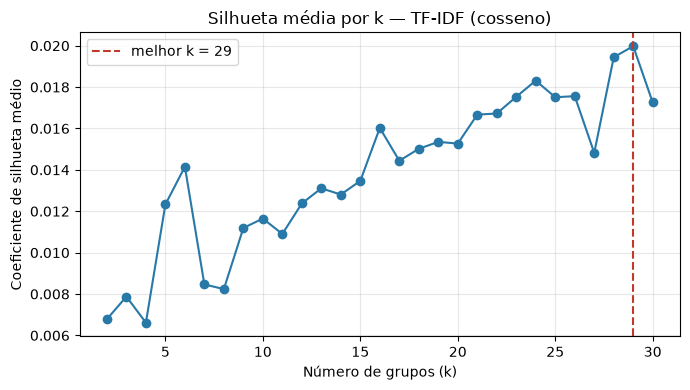

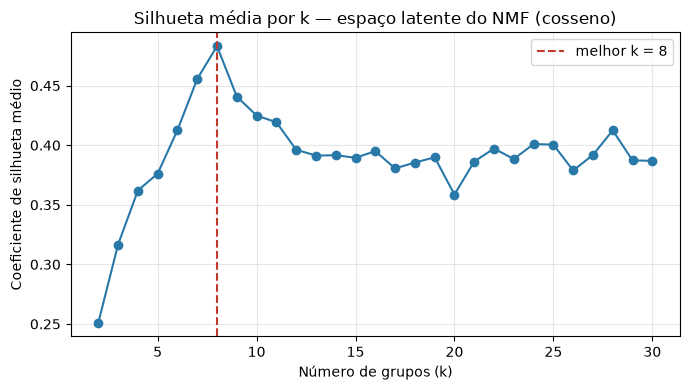

1a) TF-IDF: k = 29, silhueta média = 0.0200
1b) NMF:    k = 8, silhueta média = 0.4831

Tamanho dos grupos (TF-IDF): [199, 583, 432, 205, 1439, 359, 519, 323, 391, 517, 335, 629, 334, 1053, 390, 967, 272, 415, 329, 1046, 174, 1059, 235, 187, 612, 145, 217, 616, 658]

Tamanho dos grupos (NMF): [1920, 2039, 1764, 1358, 1364, 3446, 1695, 1054]


In [6]:
def plotar_silhueta(tabela, titulo, arquivo):
    k_melhor = int(tabela.loc[tabela['silhueta_media'].idxmax(), 'k'])
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.plot(tabela['k'], tabela['silhueta_media'], marker='o', color='#2878A8')
    ax.axvline(k_melhor, color='#C0392B', linestyle='--', label=f'melhor k = {k_melhor}')
    ax.set_xlabel('Número de grupos (k)')
    ax.set_ylabel('Coeficiente de silhueta médio')
    ax.set_title(titulo)
    ax.grid(alpha=0.3)
    ax.legend()
    fig.tight_layout()
    fig.savefig(pasta_q1 / arquivo, dpi=160)
    plt.show()
    return k_melhor

k_tfidf = plotar_silhueta(sil_tfidf, 'Silhueta média por k — TF-IDF (cosseno)', 'silhueta_tfidf.png')
k_nmf = plotar_silhueta(sil_nmf, 'Silhueta média por k — espaço latente do NMF (cosseno)', 'silhueta_nmf.png')

grupos_tfidf = rotulos_tfidf[k_tfidf]
grupos_nmf = rotulos_nmf[k_nmf]
print(f'1a) TF-IDF: k = {k_tfidf}, silhueta média = {sil_tfidf.set_index("k").loc[k_tfidf, "silhueta_media"]:.4f}')
print(f'1b) NMF:    k = {k_nmf}, silhueta média = {sil_nmf.set_index("k").loc[k_nmf, "silhueta_media"]:.4f}')

pd.DataFrame({
    'indice_base': np.arange(len(base)), 'tweet_id': base['tweet_id'],
    'grupo_tfidf': grupos_tfidf, 'grupo_nmf': grupos_nmf,
}).to_csv(pasta_q1 / 'grupos.csv', index=False, encoding='utf-8-sig')

for nome, grupos in [('TF-IDF', grupos_tfidf), ('NMF', grupos_nmf)]:
    print(f'\nTamanho dos grupos ({nome}): {np.bincount(grupos).tolist()}')

**Resultados e análise (Questão 1).**

- **TF-IDF (1a):** a silhueta média é muito baixa para todo k (entre 0,007 e 0,020) e cresce lentamente com k, sem um pico claro. O máximo em k = 29 (0,0200) fica na borda do intervalo testado (2 a 30) e é só um pouco maior que o de k = 28 (0,0194) e k = 24 (0,0183); portanto, **k = 29 não é uma escolha bem fundamentada**, e sim o melhor valor de uma curva praticamente plana. Silhuetas próximas de zero indicam que os grupos quase não se distinguem: os vetores TF-IDF têm 13 mil dimensões muito esparsas e quase ortogonais entre si, e as distâncias entre tweets curtos ficam todas parecidas. Como não removemos stopwords nesta etapa (o enunciado pede a base da lista 1), os grupos acabam separados por poucas palavras funcionais ou pelo nome da companhia (por exemplo `jetblue`, `southwestair`, `usairways`), como mostra a listagem de termos abaixo.
- **Espaço latente do NMF (1b):** a curva tem um pico nítido em **k = 8 (0,483)**, que coincide com o número de tópicos do NMF, e cai para 0,44 em k = 9 e para cerca de 0,39 a partir de k = 12. O valor é muito maior que o do TF-IDF, mas os dois números **não são comparáveis em valor absoluto**: o espaço de 8 dimensões não negativas, com cada documento concentrado em poucos tópicos, tende a formar grupos compactos perto dos eixos, o que eleva a silhueta. O resultado mostra que o k-means recupera, nesse espaço, essencialmente os próprios tópicos do NMF.
- A silhueta própria foi conferida contra `silhouette_score(metric='cosine')` do scikit-learn e coincidiu até a sexta casa decimal nas duas representações.

In [7]:
# Palavras de maior peso no centróide de cada grupo (apoio à interpretação).
vocab = np.array(vetor_tfidf.get_feature_names_out())
for nome, grupos in [('TF-IDF', grupos_tfidf), ('NMF', grupos_nmf)]:
    print(f'--- Grupos de {nome}: 6 termos de maior peso médio no TF-IDF ---')
    for g in range(grupos.max() + 1):
        media = np.asarray(X_tfidf[grupos == g].mean(axis=0)).ravel()
        print(f'  grupo {g:2d} ({(grupos == g).sum():5d} docs): {", ".join(vocab[media.argsort()[::-1][:6]])}')

--- Grupos de TF-IDF: 6 termos de maior peso médio no TF-IDF ---
  grupo  0 (  199 docs): seat, my, to, on, flight, the
  grupo  1 (  583 docs): to, from, flight, on, united, delayed
  grupo  2 (  432 docs): will, be, you, united, to, the
  grupo  3 (  205 docs): thanks, jetblue, americanair, united, usairways, southwestair
  grupo  4 ( 1439 docs): united, you, to, and, the, for
  grupo  5 (  359 docs): gate, at, the, to, for, agent
  grupo  6 (  519 docs): get, to, on, me, can, and
  grupo  7 (  323 docs): as, to, united, the, my, americanair
  grupo  8 (  391 docs): virginamerica, to, the, you, is, for
  grupo  9 (  517 docs): customer, service, your, to, united, the
  grupo 10 (  335 docs): bag, my, to, united, is, in
  grupo 11 (  629 docs): the, on, to, of, plane, is
  grupo 12 (  334 docs): please, me, to, help, you, usairways
  grupo 13 ( 1053 docs): jetblue, to, you, the, for, is
  grupo 14 (  390 docs): out, of, to, the, you, and
  grupo 15 (  967 docs): usairways, to, you, an

# Questão 2 — Projeção multidimensional com t-SNE

**Enunciado:** (a) t-SNE sobre o TF-IDF, colorindo pelos grupos da 1a; (b) variar a `perplexity` e discutir; (c) t-SNE sobre os vetores da 1b, encontrar bons valores de `perplexity` e plotar a melhor projeção de cada método, colorindo pelos grupos de 1a e 1b.

**Implementação:**

- O t-SNE do scikit-learn não aceita matriz esparsa de 14,6 mil × 15 mil de forma prática com inicialização PCA. Antes do t-SNE, reduzimos o TF-IDF a 50 dimensões com SVD truncado (`TruncatedSVD`) e normalizamos as linhas, como é usual em textos. Essa redução é só entrada do t-SNE; os grupos coloridos continuam sendo os da 1a, calculados no TF-IDF completo.
- Os vetores já têm norma 1, então a distância euclidiana ordena os pares como o cosseno. Usamos `metric='euclidean'`, `init='pca'` e `learning_rate='auto'`.
- A projeção final é feita com todos os documentos, com `random_state=42`.

In [8]:
from sklearn.decomposition import TruncatedSVD
from sklearn.manifold import TSNE, trustworthiness

svd = TruncatedSVD(n_components=50, random_state=SEMENTE)
Z_tfidf = normalize(svd.fit_transform(X_tfidf))
print(f'Variância explicada pelas 50 componentes do SVD: {svd.explained_variance_ratio_.sum():.3f}')

cache_tsne = {}

def projetar(nome, Z, perplexidade):
    chave = (nome, perplexidade)
    if chave not in cache_tsne:
        t0 = time.perf_counter()
        modelo = TSNE(n_components=2, perplexity=perplexidade, init='pca', learning_rate='auto',
                      random_state=SEMENTE, n_jobs=-1)
        cache_tsne[chave] = modelo.fit_transform(Z)
        print(f'  t-SNE {nome}, perplexity={perplexidade}: {time.perf_counter() - t0:.0f}s, '
              f'KL = {modelo.kl_divergence_:.3f}')
    return cache_tsne[chave]

def plotar_projecao(ax, emb, rotulos, titulo):
    grupos = np.unique(rotulos)
    n = len(grupos)
    if n <= 10:
        paleta = plt.get_cmap('tab10')(np.arange(n))
    elif n <= 20:
        paleta = plt.get_cmap('tab20')(np.arange(n))
    else:
        paleta = plt.get_cmap('turbo')(np.linspace(0, 1, n))
    ax.scatter(emb[:, 0], emb[:, 1], c=paleta[rotulos], s=3, linewidths=0, alpha=0.7, rasterized=True)
    for g in grupos:
        x, y = np.median(emb[rotulos == g], axis=0)
        ax.text(x, y, str(g), fontsize=9, weight='bold', ha='center', va='center',
                bbox=dict(boxstyle='round,pad=0.15', fc='white', alpha=0.75, lw=0))
    ax.set_title(titulo, fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])

Variância explicada pelas 50 componentes do SVD: 0.175


**a) t-SNE sobre o TF-IDF**, com a perplexidade padrão do scikit-learn (30), colorido pelos grupos da 1a.

  t-SNE tfidf, perplexity=30: 87s, KL = 3.120


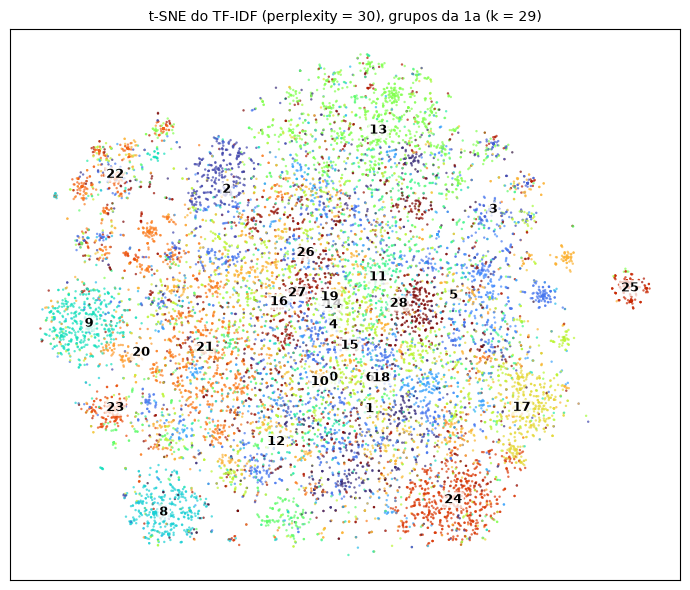

In [9]:
emb = projetar('tfidf', Z_tfidf, 30)
fig, ax = plt.subplots(figsize=(7, 6))
plotar_projecao(ax, emb, grupos_tfidf, f't-SNE do TF-IDF (perplexity = 30), grupos da 1a (k = {k_tfidf})')
fig.tight_layout()
fig.savefig(pasta_q2 / 'tsne_tfidf_perplexity30.png', dpi=160)
plt.show()

**b) Variação da perplexidade** (valores menores e maiores que o padrão 30), no mesmo experimento da 2a.

  t-SNE tfidf, perplexity=5: 52s, KL = 2.802


  t-SNE tfidf, perplexity=100: 75s, KL = 2.964


  t-SNE tfidf, perplexity=300: 112s, KL = 2.575


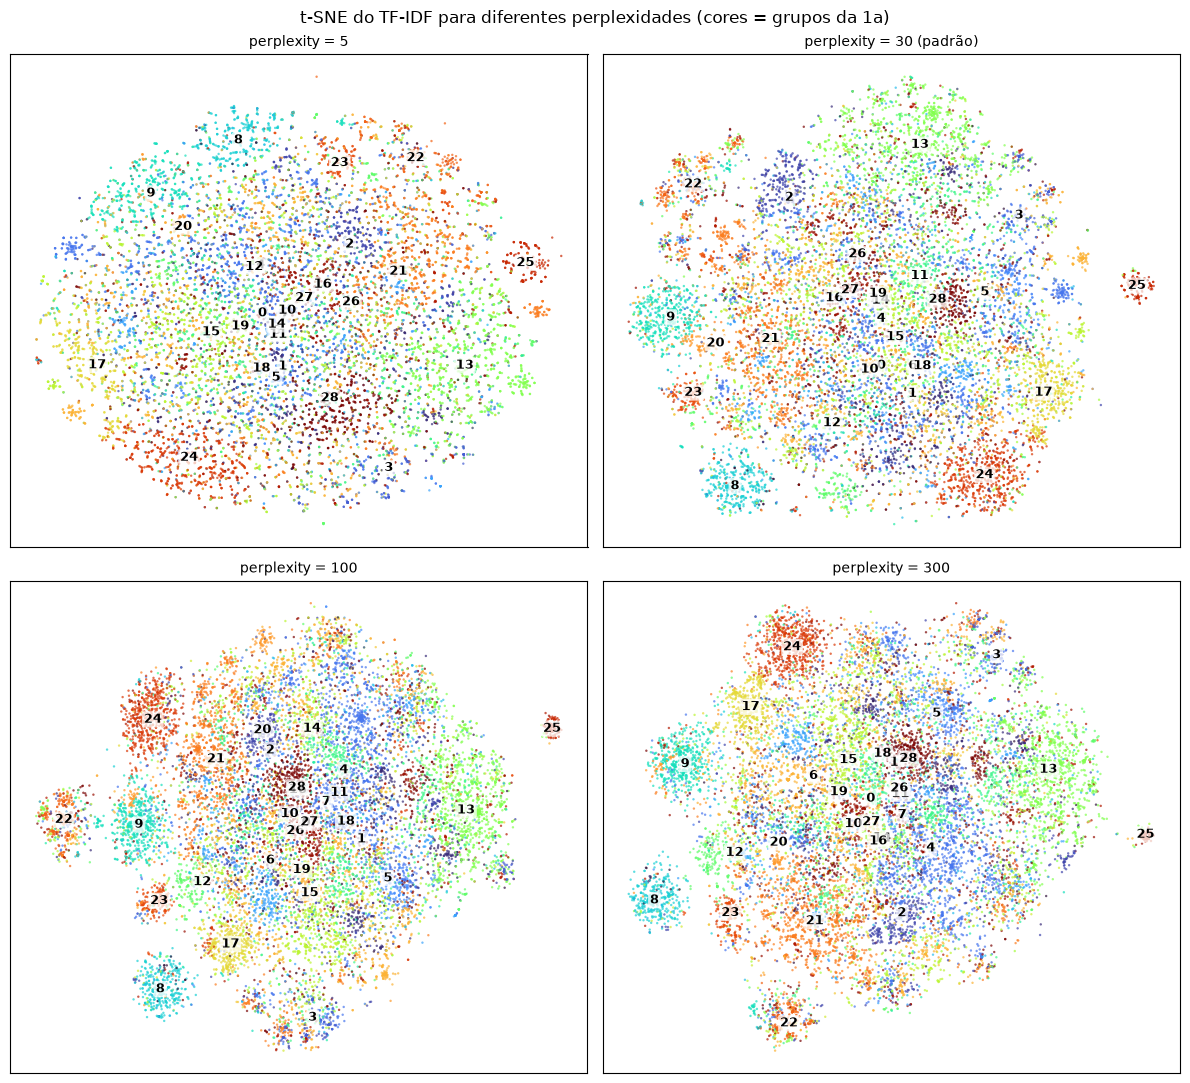

In [10]:
perplexidades_b = [5, 30, 100, 300]
fig, eixos = plt.subplots(2, 2, figsize=(12, 11))
for ax, p in zip(eixos.ravel(), perplexidades_b):
    plotar_projecao(ax, projetar('tfidf', Z_tfidf, p), grupos_tfidf, f'perplexity = {p}' + (' (padrão)' if p == 30 else ''))
fig.suptitle('t-SNE do TF-IDF para diferentes perplexidades (cores = grupos da 1a)')
fig.tight_layout()
fig.savefig(pasta_q2 / 'tsne_tfidf_perplexidades.png', dpi=130)
plt.show()

**Resultado da 2a e análise da 2b (perplexidade).** Com a perplexidade padrão (30), o t-SNE do TF-IDF separa algumas ilhas bem definidas (grupos 8, 9, 24 e 25, que reúnem tweets sobre `virginamerica`, atendimento ao cliente, cancelamentos e um bloco de retweets repetidos), mas a maior parte dos documentos forma uma grande massa central em que os 29 grupos se misturam. Isso é coerente com a silhueta de 0,02 da 1a: os grupos do k-means não correspondem a regiões separadas do espaço.

Efeito da perplexidade:

- **Valor baixo (5):** a projeção fica difusa e sem separação global; cada ponto só considera cerca de 5 vizinhos, então aparecem muitos micro-agrupamentos locais (pontos pequenos soltos, pares e trios) e as ilhas que existiam em 30 se dissolvem, o que torna o resultado mais sensível a ruído.
- **Valor padrão (30):** equilíbrio entre estrutura local e global; é onde as ilhas aparecem com mais nitidez em relação ao fundo.
- **Valores altos (100 e 300):** cada ponto considera muitos vizinhos, então a projeção prioriza a estrutura global; as ilhas pequenas (22, 23, 25) encolhem ou ficam isoladas nas bordas, os grupos grandes ocupam regiões mais amplas e contínuas e os detalhes locais se perdem. O custo também sobe (112 s em 300 contra 52 s em 5 e 87 s em 30, nesta máquina).

O valor da divergência KL impresso (2,80; 3,12; 2,96; 2,58 para 5, 30, 100 e 300) não serve para comparar perplexidades, pois muda com a própria definição de vizinhança.

**c) Escolha da perplexidade e comparação dos dois métodos.**

Para escolher a perplexidade de forma objetiva, usamos a **confiabilidade** (`trustworthiness`, scikit-learn), que mede a fração dos vizinhos mais próximos no espaço de origem (15 vizinhos) que se preservam na projeção. Ela é calculada para os dois métodos sobre a mesma subamostra aleatória fixa de 5.000 documentos, para manter o custo baixo, e comparada com a inspeção visual. Como o valor ideal da perplexidade cresce com o tamanho da base, a escolha na subamostra é uma aproximação; as projeções finais usam toda a base. O espaço de origem de cada método é o que entra no t-SNE: o SVD de 50 dimensões normalizado para o TF-IDF e os 8 tópicos normalizados do NMF.

tfidf  perplexity=  5: confiabilidade = 0.9074


tfidf  perplexity= 15: confiabilidade = 0.9317


tfidf  perplexity= 30: confiabilidade = 0.9400


tfidf  perplexity= 50: confiabilidade = 0.9476


tfidf  perplexity=100: confiabilidade = 0.9499


...

nmf    perplexity= 15: confiabilidade = 0.9972


nmf    perplexity= 30: confiabilidade = 0.9975


nmf    perplexity= 50: confiabilidade = 0.9971


nmf    perplexity=100: confiabilidade = 0.9966


nmf    perplexity=200: confiabilidade = 0.9944


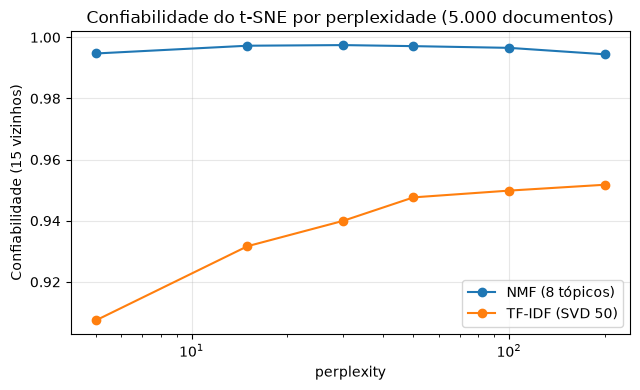

Perplexidade escolhida: {'nmf': 30, 'tfidf': 200}


In [11]:
rng = np.random.default_rng(SEMENTE)
indices_sub = np.sort(rng.choice(len(base), size=5000, replace=False))
perplexidades_c = [5, 15, 30, 50, 100, 200]
entradas = {'tfidf': Z_tfidf, 'nmf': X_nmf}

linhas = []
for nome, Z in entradas.items():
    Z_sub = Z[indices_sub]
    for p in perplexidades_c:
        emb_sub = TSNE(n_components=2, perplexity=p, init='pca', learning_rate='auto',
                       random_state=SEMENTE, n_jobs=-1).fit_transform(Z_sub)
        confiabilidade = trustworthiness(Z_sub, emb_sub, n_neighbors=15)
        linhas.append({'representacao': nome, 'perplexity': p, 'confiabilidade': float(confiabilidade)})
        print(f'{nome:6s} perplexity={p:3d}: confiabilidade = {confiabilidade:.4f}')

tabela_perp = pd.DataFrame(linhas)
tabela_perp.to_csv(pasta_q2 / 'confiabilidade_perplexidade.csv', index=False, encoding='utf-8-sig')

fig, ax = plt.subplots(figsize=(6.5, 4))
for nome, grupo in tabela_perp.groupby('representacao'):
    ax.plot(grupo['perplexity'], grupo['confiabilidade'], marker='o', label={'tfidf': 'TF-IDF (SVD 50)', 'nmf': 'NMF (8 tópicos)'}[nome])
ax.set_xscale('log')
ax.set_xlabel('perplexity')
ax.set_ylabel('Confiabilidade (15 vizinhos)')
ax.set_title('Confiabilidade do t-SNE por perplexidade (5.000 documentos)')
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig(pasta_q2 / 'confiabilidade_perplexidade.png', dpi=160)
plt.show()

melhor_perp = {nome: int(g.loc[g['confiabilidade'].idxmax(), 'perplexity']) for nome, g in tabela_perp.groupby('representacao')}
print('Perplexidade escolhida:', melhor_perp)

Projeções finais, base completa:


  t-SNE tfidf, perplexity=200: 91s, KL = 2.756


  t-SNE nmf, perplexity=30: 47s, KL = 1.295


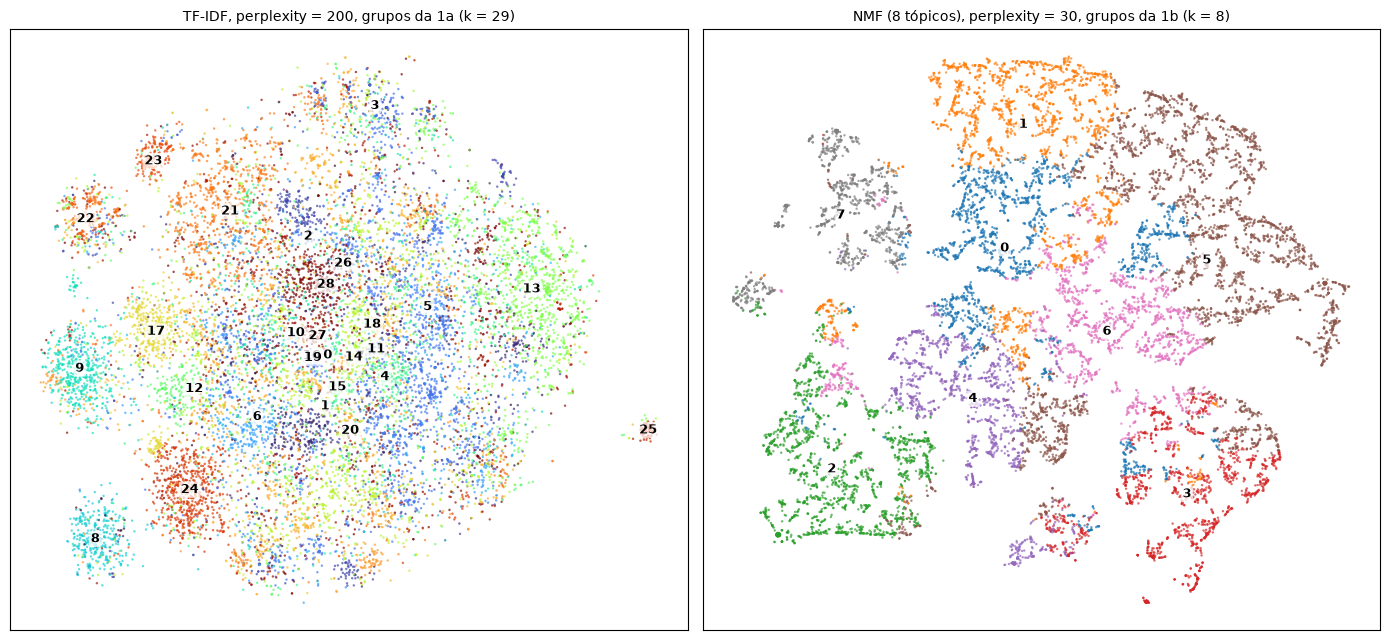

In [12]:
print('Projeções finais, base completa:')
emb_tfidf_final = projetar('tfidf', Z_tfidf, melhor_perp['tfidf'])
emb_nmf_final = projetar('nmf', X_nmf, melhor_perp['nmf'])

fig, eixos = plt.subplots(1, 2, figsize=(14, 6.5))
plotar_projecao(eixos[0], emb_tfidf_final, grupos_tfidf,
                f'TF-IDF, perplexity = {melhor_perp["tfidf"]}, grupos da 1a (k = {k_tfidf})')
plotar_projecao(eixos[1], emb_nmf_final, grupos_nmf,
                f'NMF (8 tópicos), perplexity = {melhor_perp["nmf"]}, grupos da 1b (k = {k_nmf})')
fig.tight_layout()
fig.savefig(pasta_q2 / 'melhores_projecoes.png', dpi=150)
plt.show()

pd.DataFrame({'indice_base': np.arange(len(base)),
              'tfidf_x': emb_tfidf_final[:, 0], 'tfidf_y': emb_tfidf_final[:, 1],
              'nmf_x': emb_nmf_final[:, 0], 'nmf_y': emb_nmf_final[:, 1]}
             ).to_csv(pasta_q2 / 'coordenadas_melhores_projecoes.csv', index=False)

**Resultado da 2c e análise.**

- **Escolha da perplexidade:** para o NMF, a confiabilidade é praticamente igual (≥ 0,994) em todos os valores e atinge o máximo em **30 (0,9975)**. Isso era esperado, pois o espaço de origem já tem só 8 dimensões e quase não há o que se perder na projeção. Para o TF-IDF, a confiabilidade cresce com a perplexidade e o máximo ocorre em **200 (0,9518)**, na borda da grade testada; o ganho entre 100 (0,9499) e 200 é pequeno, então perplexidades de 100 a 200 são equivalentes na prática. A confiabilidade foi calculada em uma subamostra de 5.000 documentos, e os valores **não são comparáveis entre os dois métodos**, que partem de espaços diferentes (50 e 8 dimensões).
- **Comparação visual:** na projeção do NMF, os grupos da 1b ocupam regiões contíguas e relativamente bem delimitadas (por exemplo 2, 7 e 1), com sobreposição parcial entre vizinhos (3, 5 e 6), e os pontos se espalham em faixas, como esperado de documentos que variam continuamente entre poucos tópicos. Na projeção do TF-IDF, as poucas ilhas isoladas se destacam, mas a massa central continua misturada. Os dois resultados concordam com as silhuetas da Questão 1: o NMF tem estrutura de grupos bem mais clara que o TF-IDF.

# Questão 3 — Buscadores de palavras e documentos com word2vec

**Enunciado:** (a) escolher e aplicar um modelo word2vec pré-treinado compatível com o idioma; (b) com 5 palavras de consulta ausentes dos textos, encontrar para cada uma as 3 palavras mais parecidas do conjunto de textos e exibir os documentos onde aparecem; (c) implementar a busca de documentos pela média das 5 menores distâncias (DM5). Sempre com distância do cosseno, sem stemização e com remoção de stopwords.

**a) Modelo escolhido:** `word2vec-google-news-300`, o word2vec de 300 dimensões treinado pelo Google em cerca de 100 bilhões de palavras de notícias em **inglês**, idioma dos tweets. Ele tem 3 milhões de entradas; carregamos as **500 mil mais frequentes** (cerca de 600 MB em memória), o que cobre o vocabulário comum dos tweets e cabe em máquinas modestas. O arquivo (~1,6 GB) é baixado automaticamente para `modelos/` na primeira execução. Como o gensim não instala no Python 3.14, lemos o formato binário do word2vec direto com NumPy.

**Normalização compatível com o modelo:** o vocabulário do Google News distingue maiúsculas de minúsculas, e o pré-processamento da Atividade 1 já converte tudo para minúsculas, então só entram as palavras cuja forma minúscula existe no modelo. Palavras sem vetor são descartadas, assim como as stopwords (lista em inglês do scikit-learn). Não há stemização. As palavras de consulta passam pela mesma normalização. Os vetores são normalizados para norma 1, de modo que a distância do cosseno é `1 − produto interno`.

In [13]:
import gzip
import urllib.request
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

URL_MODELO = 'https://github.com/RaRe-Technologies/gensim-data/releases/download/word2vec-google-news-300/word2vec-google-news-300.gz'
caminho_modelo = Path('modelos/word2vec-google-news-300.gz')
LIMITE_PALAVRAS = 500_000

if not caminho_modelo.is_file():
    caminho_modelo.parent.mkdir(exist_ok=True)
    print('Baixando o modelo (~1,6 GB)...')
    urllib.request.urlretrieve(URL_MODELO, caminho_modelo)

def carregar_word2vec(caminho, limite):
    # Lê o formato binário do word2vec (cabeçalho "n d", depois palavra, espaço e d float32).
    with gzip.open(caminho, 'rb') as f:
        total, dimensao = map(int, f.readline().split())
        palavras = []
        vetores = np.empty((limite, dimensao), dtype=np.float32)
        for i in range(limite):
            caracteres = bytearray()
            while True:
                c = f.read(1)
                if c == b' ':
                    break
                if c != b'\n':
                    caracteres += c
            palavras.append(caracteres.decode('utf-8', errors='ignore'))
            vetores[i] = np.frombuffer(f.read(4 * dimensao), dtype=np.float32)
    return palavras, vetores

t0 = time.perf_counter()
palavras_modelo, vetores_modelo = carregar_word2vec(caminho_modelo, LIMITE_PALAVRAS)
vetores_modelo /= np.maximum(np.linalg.norm(vetores_modelo, axis=1, keepdims=True), 1e-12)
indice_modelo = {p: i for i, p in enumerate(palavras_modelo)}
print(f'Modelo carregado: {len(palavras_modelo)} palavras x {vetores_modelo.shape[1]} dimensões em {time.perf_counter() - t0:.0f}s')

Modelo carregado: 500000 palavras x 300 dimensões em 22s


In [14]:
STOPWORDS = set(ENGLISH_STOP_WORDS)

todos_tokens = set(t for tokens in base['tokens'] for t in tokens)

def normalizar_tokens(tokens):
    # Remove stopwords e palavras sem vetor no modelo; mantém as palavras distintas, na ordem de aparição.
    return list(dict.fromkeys(t for t in tokens if t not in STOPWORDS and t in indice_modelo))

base['palavras_q3'] = base['tokens'].map(normalizar_tokens)   # V(d)
com_vetor = base['palavras_q3'].map(len) > 0
print(f'Documentos com V(d) vazio (desconsiderados na busca): {int((~com_vetor).sum())}')

# Vocabulário da base que o modelo conhece, e matriz de vetores correspondente.
vocabulario_base = sorted(set(p for lista in base['palavras_q3'] for p in lista))
posicao_vocab = {p: i for i, p in enumerate(vocabulario_base)}
matriz_vocab = vetores_modelo[[indice_modelo[p] for p in vocabulario_base]]

tokens_sem_stop = {t for t in todos_tokens if t not in STOPWORDS}
print(f'Palavras distintas da base (sem stopwords): {len(tokens_sem_stop)}')
print(f'  com vetor no modelo: {len(vocabulario_base)} ({len(vocabulario_base) / len(tokens_sem_stop):.1%})')
print(f'  sem vetor (descartadas): {len(tokens_sem_stop) - len(vocabulario_base)}, por exemplo: {sorted(tokens_sem_stop - set(vocabulario_base))[:12]}')

Documentos com V(d) vazio (desconsiderados na busca): 84
Palavras distintas da base (sem stopwords): 13247
  com vetor no modelo: 7728 (58.3%)
  sem vetor (descartadas): 5519, por exemplo: ['aaaand', 'aaadvantage', 'aaalwayslate', 'aaba', 'aacom', 'aacustomerservice', 'aadavantage', 'aadelay', 'aadfw', 'aadv', 'aadvantage', 'aafail']


**b) Palavras de consulta e palavras mais parecidas.** As consultas são escolhidas de uma lista de candidatas ligadas ao tema da base (viagens aéreas) e só são aceitas se **não aparecerem em nenhum tweet** (nem como stopword) e tiverem vetor no modelo.

In [15]:
candidatas = ['jetliner', 'hijacking', 'parachute', 'helicopter', 'aviator', 'airship', 'blimp']
consultas = []
for palavra in candidatas:
    if palavra in todos_tokens:
        print(f'  descartada (aparece nos textos): {palavra}')
    elif palavra not in indice_modelo:
        print(f'  descartada (sem vetor no modelo): {palavra}')
    elif len(consultas) < 5:
        consultas.append(palavra)
assert len(consultas) == 5 and not (set(consultas) & todos_tokens)
print('Palavras de consulta:', consultas)

def distancias_ao_vocabulario(palavra):
    return 1.0 - matriz_vocab @ vetores_modelo[indice_modelo[palavra]]

# Índice invertido: palavra -> documentos em que aparece.
documentos_da_palavra = {}
for indice_doc, lista in base['palavras_q3'].items():
    for p in lista:
        documentos_da_palavra.setdefault(p, []).append(indice_doc)

linhas_resumo, linhas_docs = [], []
for consulta in consultas:
    dist = distancias_ao_vocabulario(consulta)
    mais_proximas = np.argsort(dist, kind='stable')[:3]
    print(f'\n=== Consulta: {consulta!r} ===')
    for posicao in mais_proximas:
        palavra = vocabulario_base[posicao]
        docs = documentos_da_palavra[palavra]
        print(f'  {palavra!r}: distância do cosseno = {dist[posicao]:.4f}, aparece em {len(docs)} documento(s)')
        for d in docs[:3]:
            print(f'      [{d}] {base.loc[d, "text"]!r}')
        linhas_resumo.append({'consulta': consulta, 'palavra_parecida': palavra,
                              'distancia_cosseno': round(float(dist[posicao]), 4),
                              'n_documentos': len(docs),
                              'exemplos': ' || '.join(base.loc[d, 'text'] for d in docs[:3])})
        linhas_docs += [{'consulta': consulta, 'palavra_parecida': palavra, 'indice_base': d,
                         'tweet_id': base.loc[d, 'tweet_id']} for d in docs]

pd.DataFrame(linhas_resumo).to_csv(pasta_q3 / 'palavras_parecidas.csv', index=False, encoding='utf-8-sig')
pd.DataFrame(linhas_docs).to_csv(pasta_q3 / 'documentos_3b.csv', index=False, encoding='utf-8-sig')
print(f'\nLista completa de documentos por palavra: {len(linhas_docs)} linhas em documentos_3b.csv')

Palavras de consulta: ['jetliner', 'hijacking', 'parachute', 'helicopter', 'aviator']

=== Consulta: 'jetliner' ===
  'airliner': distância do cosseno = 0.1496, aparece em 1 documento(s)
      [5927] '@SouthwestAir your A-list program is a complete JOKE! Your company does not value loyal customers.Time to look for another "go-to" airliner'
  'plane': distância do cosseno = 0.2794, aparece em 584 documento(s)
      [74] "@VirginAmerica not worried, it's been a great ride in a new plane with great crew. All airlines should be like this."
      [97] '@VirginAmerica - Let 2 scanned in passengers leave the plane than told someone to remove their bag from 1st class bin? #uncomfortable'
      [115] '@VirginAmerica should I be concerned that I am about to fly on a plane that needs to be delayed due to a "tech stop"?'
  'airplane': distância do cosseno = 0.2934, aparece em 23 documento(s)
      [851] "@united system failure again = bad trend.  Software projects are like flying an airplane; ther


=== Consulta: 'parachute' ===
  'plane': distância do cosseno = 0.5441, aparece em 584 documento(s)
      [74] "@VirginAmerica not worried, it's been a great ride in a new plane with great crew. All airlines should be like this."
      [97] '@VirginAmerica - Let 2 scanned in passengers leave the plane than told someone to remove their bag from 1st class bin? #uncomfortable'
      [115] '@VirginAmerica should I be concerned that I am about to fly on a plane that needs to be delayed due to a "tech stop"?'
  'balloons': distância do cosseno = 0.5679, aparece em 1 documento(s)
      [12986] '@AmericanAir Hello, question, How many balloons do you think it will take to life up one of your planes?'
  'airplane': distância do cosseno = 0.5889, aparece em 23 documento(s)
      [851] "@united system failure again = bad trend.  Software projects are like flying an airplane; there's no such thing as an emergency takeoff."
      [1387] '@united I wanna be ride United airline! I love airplane'
    


Lista completa de documentos por palavra: 2016 linhas em documentos_3b.csv


**Análise (3b).** A busca por vizinhos de palavras funciona bem quando a consulta tem sinônimos próximos no vocabulário da base: `jetliner` retorna `airliner` (distância 0,15), `plane` e `airplane`; `helicopter` retorna `plane`, `aircraft` e `airplane`. Quando não há sinônimo, as palavras retornadas são apenas as mais próximas disponíveis, com distâncias altas e relação fraca com o sentido da consulta: `hijacking` retorna `hostage`, `terror` e `killing` (≈ 0,62), que nos tweets aparecem em sentido figurado ("held hostage", "killing me"); `parachute` retorna `plane`, `balloons` e `airplane`; e `aviator` retorna `sailor`, `pilots` e `pilot`. A palavra `plane` domina porque é frequente, aparece em 584 documentos e fica próxima de quase todo o tema de aviação. Como o modelo foi treinado em notícias, não conhece 41,7% das palavras distintas da base (nomes de contas, hashtags, erros de digitação), que ficam fora da busca.

**c) Busca de documentos por DM5.** Para cada documento `d` com `V(d)` não vazio, `L5(d, w)` são as (até) cinco palavras de `V(d)` mais próximas de `w`; `DM5(d, w)` é a média das distâncias do cosseno entre `w` e essas palavras; os três documentos de menor `DM5` são recuperados. Em empates, prevalece o documento de menor índice. A função é testada antes com um exemplo pequeno, incluindo o caso de menos de cinco palavras.

In [16]:
def dm5_documento(dist_vocab, ids_palavras):
    # Média das (até) 5 menores distâncias à consulta entre as palavras do documento.
    distancias = np.sort(dist_vocab[ids_palavras])[:5]
    return float(distancias.mean()), distancias

# Testes: menos de 5 palavras usa todas; com mais de 5 usa só as 5 menores.
dist_teste = np.array([0.1, 0.9, 0.5, 0.3, 0.7, 0.2, 0.8])
assert abs(dm5_documento(dist_teste, [0, 1])[0] - 0.5) < 1e-12
assert abs(dm5_documento(dist_teste, [0, 1, 2, 3, 4, 5, 6])[0] - np.mean([0.1, 0.2, 0.3, 0.5, 0.7])) < 1e-12

ids_documentos = {i: np.array([posicao_vocab[p] for p in lista]) for i, lista in base['palavras_q3'].items() if lista}
print(f'Documentos considerados: {len(ids_documentos)} de {len(base)}')

linhas_3c = []
for consulta in consultas:
    dist = distancias_ao_vocabulario(consulta)
    indices = np.array(list(ids_documentos))
    dm5 = np.array([dm5_documento(dist, ids_documentos[i])[0] for i in indices])
    melhores = np.argsort(dm5, kind='stable')[:3]
    print(f'\n=== Consulta: {consulta!r} ===')
    for ordem, pos in enumerate(melhores, start=1):
        d = int(indices[pos])
        _, distancias = dm5_documento(dist, ids_documentos[d])
        palavras_l5 = [vocabulario_base[j] for j in ids_documentos[d][np.argsort(dist[ids_documentos[d]], kind='stable')[:5]]]
        print(f'  {ordem}. [{d}] DM5 = {dm5[pos]:.4f} | L5 = {palavras_l5}\n     {base.loc[d, "text"]!r}')
        linhas_3c.append({'consulta': consulta, 'posicao': ordem, 'indice_base': d, 'tweet_id': base.loc[d, 'tweet_id'],
                          'dm5': round(float(dm5[pos]), 4), 'palavras_l5': ', '.join(palavras_l5),
                          'texto': base.loc[d, 'text']})

pd.DataFrame(linhas_3c).to_csv(pasta_q3 / 'documentos_3c.csv', index=False, encoding='utf-8-sig')

Documentos considerados: 14556 de 14640



=== Consulta: 'jetliner' ===
  1. [7471] DM5 = 0.3652 | L5 = ['plane', 'flight']
     '@JetBlue the whole plane. Flight 561 from LGA to PBI http://t.co/4Ktk2hsmGy'
  2. [7172] DM5 = 0.4231 | L5 = ['plane', 'airplane', 'flying']
     '@JetBlue what else on this plane is duct-taped?? #ohboy #shouldigetoutandpush #airplane #flying… http://t.co/R9ZsVzuRLw'
  3. [129] DM5 = 0.4510 | L5 = ['flight']
     '@VirginAmerica is flight 882 Cancelled Flightled and what do I do if it is?'



=== Consulta: 'hijacking' ===
  1. [9834] DM5 = 0.7183 | L5 = ['hostage', 'passengers', 'crash', 'plane', 'computer']
     '@USAirways holding your passengers hostage during your computer crash is not customer friendly, let us off the plane or get us moving'
  2. [129] DM5 = 0.7478 | L5 = ['flight']
     '@VirginAmerica is flight 882 Cancelled Flightled and what do I do if it is?'
  3. [5854] DM5 = 0.7478 | L5 = ['flight']
     '@SouthwestAir flight # 317'



=== Consulta: 'parachute' ===
  1. [7172] DM5 = 0.5954 | L5 = ['plane', 'airplane', 'flying']
     '@JetBlue what else on this plane is duct-taped?? #ohboy #shouldigetoutandpush #airplane #flying… http://t.co/R9ZsVzuRLw'
  2. [7471] DM5 = 0.5977 | L5 = ['plane', 'flight']
     '@JetBlue the whole plane. Flight 561 from LGA to PBI http://t.co/4Ktk2hsmGy'
  3. [129] DM5 = 0.6512 | L5 = ['flight']
     '@VirginAmerica is flight 882 Cancelled Flightled and what do I do if it is?'



=== Consulta: 'helicopter' ===
  1. [7172] DM5 = 0.4851 | L5 = ['plane', 'airplane', 'flying']
     '@JetBlue what else on this plane is duct-taped?? #ohboy #shouldigetoutandpush #airplane #flying… http://t.co/R9ZsVzuRLw'
  2. [7471] DM5 = 0.4937 | L5 = ['plane', 'flight']
     '@JetBlue the whole plane. Flight 561 from LGA to PBI http://t.co/4Ktk2hsmGy'
  3. [4410] DM5 = 0.5973 | L5 = ['plane', 'freezing']
     '@SouthwestAir freezing in the plane'



=== Consulta: 'aviator' ===
  1. [7172] DM5 = 0.6071 | L5 = ['airplane', 'plane', 'flying']
     '@JetBlue what else on this plane is duct-taped?? #ohboy #shouldigetoutandpush #airplane #flying… http://t.co/R9ZsVzuRLw'
  2. [7471] DM5 = 0.6268 | L5 = ['plane', 'flight']
     '@JetBlue the whole plane. Flight 561 from LGA to PBI http://t.co/4Ktk2hsmGy'
  3. [129] DM5 = 0.6299 | L5 = ['flight']
     '@VirginAmerica is flight 882 Cancelled Flightled and what do I do if it is?'


**Análise (3c).** O DM5 recupera documentos cujas palavras estão próximas da consulta, mas tem um viés de tamanho: se `V(d)` tem menos de cinco palavras, a média usa todas, então um tweet curto com uma única palavra próxima obtém DM5 baixo. É o caso do documento 129 (`flight`, DM5 = 0,451 para `jetliner`), que aparece entre os três primeiros para quatro das cinco consultas, ao lado dos documentos 7172 e 7471, que contêm `plane` e `airplane`. Para `hijacking`, o primeiro resultado (documento 9834: "holding your passengers hostage during your computer crash...") é o mais coerente com a consulta, pois reúne `hostage`, `passengers` e `crash`; os dois seguintes empatam em DM5 com uma única palavra genérica (`flight`), o que mostra a fraqueza do método para consultas sem sinônimos na base. Em relação à 3b, que lista **todos** os documentos que contêm as palavras parecidas, o DM5 faz uma classificação dos documentos por proximidade média e retorna só três, o que é mais útil para consultas, mas favorece documentos curtos e genéricos.